<a href="https://colab.research.google.com/github/joannasarah015-commits/metodosn-meros1/blob/main/Nwtonfinish.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#METODO, DIFERENCIAS DIVIDIDAS DE NEWTON

Dados $n + 1$ puntos distintos $x_0, x_1, \dots, x_n$ y los valores $f(x_0), f(x_1), \dots, f(x_n)$ con $F_{i,0} = f(x_i)$, el algoritmo calcula las diferencias divididas para $i = 1, \dots, n$ y $j = 1, \dots, i$:

$$F_{i,j} = \frac{F_{i,j-1} - F_{i-1,j-1}}{x_i - x_{i-j}}$$

Los coeficientes del polinomio interpolante de Newton quedan en la diagonal principal $F_{0,0}, F_{1,1}, \dots, F_{n,n}$:

$$P_n(x) = F_{0,0} + \sum_{i=1}^{n} F_{i,i} \prod_{j=0}^{i-1} (x - x_j)$$


**Ejemplo 1.** Construir la tabla de diferencias divididas y el polinomio $P_4(x)$ para los nodos $x = [1.0, 1.3, 1.6, 1.9, 2.2]$ y $f(x) = [0.7651977, 0.6200860, 0.4554022, 0.2818186, 0.1103623]$, obteniendo $P_4(1.5) = 0.5118200$.

In [1]:
import numpy as np
import pandas as pd
import sympy as sp
import matplotlib.pyplot as plt

In [2]:
x_nodos = np.array([1.0, 1.3, 1.6, 1.9, 2.2], dtype=float)
y_nodos = np.array([0.7651977, 0.6200860, 0.4554022, 0.2818186, 0.1103623], dtype=float)
x_eval = 1.5

In [3]:
def diferencias_divididas(xi, yi):
    m = len(xi)
    F = np.zeros((m, m))
    F[:, 0] = yi

    for j in range(1, m):
        for i in range(j, m):
            F[i, j] = (F[i, j - 1] - F[i - 1, j - 1]) / (xi[i] - xi[i - j])

    coefs = [F[k, k] for k in range(m)]
    return F, coefs

In [4]:
tabla_F, a_coef = diferencias_divididas(x_nodos, y_nodos)

Hacemos la tabla con coeficientes

In [5]:
encabezados = [f"Orden {j}" for j in range(len(x_nodos))]
tabla_df = pd.DataFrame(tabla_F, columns=encabezados)
tabla_df.insert(0, "x_i", x_nodos)

for fila in range(len(x_nodos)):
    for col in range(fila + 1, len(x_nodos)):
        tabla_df.iloc[fila, col + 1] = np.nan

pd.set_option("display.precision", 7)
print("Tabla de diferencias divididas:")
display(tabla_df.fillna(""))

print("\nCoeficientes del polinomio de Newton:")
for idx, val in enumerate(a_coef):
    print(f"a_{idx} = {val:.7f}")

Tabla de diferencias divididas:


,x_i,Orden 0,Orden 1,Orden 2,Orden 3,Orden 4
0,1.0,0.7651977,,,,
1,1.3,0.6200860,-0.4837057,,,
2,1.6,0.4554022,-0.548946,-0.1087339,,
3,1.9,0.2818186,-0.578612,-0.0494433,0.0658784,
4,2.2,0.1103623,-0.571521,0.0118183,0.0680685,0.0018251



Coeficientes del polinomio de Newton:
a_0 = 0.7651977
a_1 = -0.4837057
a_2 = -0.1087339
a_3 = 0.0658784
a_4 = 0.0018251


aqui construiremos el polinmio de newton.

In [6]:
x_simb = sp.Symbol("x")
polinomio = a_coef[0]
producto = 1

for k in range(1, len(a_coef)):
    producto *= (x_simb - x_nodos[k - 1])
    polinomio += a_coef[k] * producto

valor_eval = float(polinomio.subs(x_simb, x_eval))
print("Polinomio de Newton:")
display(polinomio)
print(f"\nEvaluación en x = {x_eval}: P_{len(a_coef)-1}({x_eval}) = {valor_eval:.7f}")

Polinomio de Newton:


-0.483705666666666*x + 0.00182510288066044*(x - 1.9)*(x - 1.6)*(x - 1.3)*(x - 1.0) + 0.0658783950617283*(x - 1.6)*(x - 1.3)*(x - 1.0) - 0.108733888888889*(x - 1.3)*(x - 1.0) + 1.24890336666667


Evaluación en x = 1.5: P_4(1.5) = 0.5118200


Definimos y dibujamos la grafica

In [7]:
f_pol = sp.lambdify(x_simb, polinomio, "numpy")
x_curva = np.linspace(0.9, 2.3, 100)
y_curva = f_pol(x_curva)

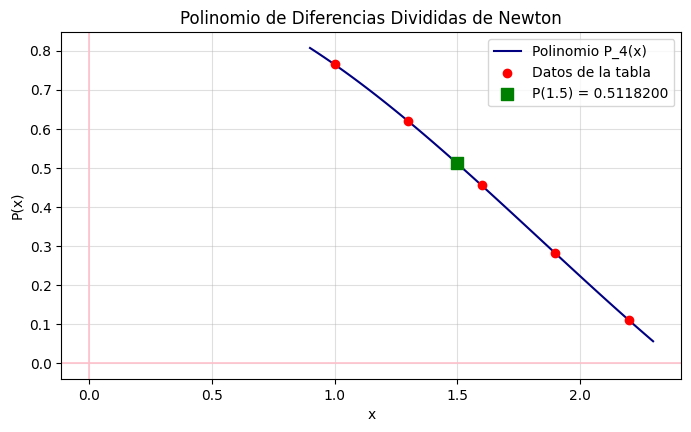

In [8]:
plt.figure(figsize=(8, 4.5))
plt.axhline(0, color="pink", linewidth=1.2)
plt.axvline(0, color="pink", linewidth=1.2)
plt.plot(x_curva, y_curva, label=f"Polinomio P_{len(a_coef)-1}(x)", color="navy")
plt.scatter(x_nodos, y_nodos, color="red", label="Datos de la tabla", zorder=5)
plt.scatter([x_eval], [valor_eval], color="green", marker="s", s=70,
            label=f"P({x_eval}) = {valor_eval:.7f}", zorder=6)
plt.title("Polinomio de Diferencias Divididas de Newton")
plt.xlabel("x")
plt.ylabel("P(x)")
plt.grid(True, alpha=0.4)
plt.legend()
plt.show()